# SAT benchmark — SATBench

Everything the paper reports for the speed–accuracy trade-off benchmark:

| Output | File |
|---|---|
| `SAT_bench.pdf` — accuracy vs response deadline, averaged over perturbation levels, for every model against the human noise ceiling | `outputs/sat/SAT_bench.pdf` |
| Table `tab:sat_perobs` — RMSE / $r$ / $\mathcal{K}$ per perturbation level | `outputs/sat/sat_perobs_table.tex` |
| Table `tab:sat_global` — the same metrics averaged over levels, with bootstrap CIs | `outputs/sat/sat_global_table.tex` |

Models: **NRM**, **CNet (par.)**, **CNet (ser.)**, **ConvRNN**, **MSDNet**,
**SCAN**. Conditions: **color-blur**, **color-gray**, **gray-noise**.

This notebook evaluates NRM itself and then reads each competitor's detail
files from `outputs/sat/<task>/<model>/`.
Highlighting in both tables is computed here from those files.

With `REFRESH = True` (or `REFRESH_WEIGHTS = True`) every output is written
with the `_REFRESH` suffix instead (per-model detail in
`outputs/sat/<task>/<model>_REFRESH/`), next to the reference ones.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT))

# Canonical result layout (shared with ranking.ipynb), tables and figures.
from scripts import figures, results_io, tables
from scripts.results_io import satbench_scalars, save_sat_metrics

OUTDIR = results_io.benchmark_dir('sat')
OUTDIR.mkdir(parents=True, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

# REFRESH = True re-evaluates every model from its weights instead of reusing
# the per-model detail in outputs/sat/.  REFRESH_WEIGHTS = True evaluates the
# retrained weights (*_REFRESH.pt[h]) and implies REFRESH.  Either flag adds a
# _REFRESH suffix to every output file, leaving the reference outputs untouched.
REFRESH = False
REFRESH_WEIGHTS = False

REFRESH = REFRESH or REFRESH_WEIGHTS
TAG = results_io.refresh_tag(REFRESH)

TASKS = results_io.SAT_TASKS          # color-blur, color-gray, gray-noise
TASK_LABELS = figures.SAT_TASK_LABELS
N_CHOICES = 16                        # 16-way ImageNet categorisation

# SDE samples per (image, deadline) in the level analysis.
N_RT_SAMPLES = 50

BATCH_SIZE = 256
N_RT_SAMPLES_COLLECT = 100

Device: cuda


## 1. NRM on each perturbation condition

`sat_level_curves.json` and `satbench_metrics_full.json` contain per-condition accuracy and RT curves for each (level, deadline) pair.

In [2]:
from torch.utils.data import DataLoader

from datasets.sat.loader import SATDataset, sat_collate_fn
from nrm.config import build_model
from scripts.eval_sat import run_sat_level_analysis
from scripts.eval_sat import ModelEvaluator

PERT_TO_WEIGHT = {
    'color-blur': ROOT / 'nrm' / 'weights' / 'NRM_sat_blur.pth',
    'color-gray': ROOT / 'nrm' / 'weights' / 'NRM_sat_color.pth',
    'gray-noise': ROOT / 'nrm' / 'weights' / 'NRM_sat_noise.pth',
}
if REFRESH_WEIGHTS:
    # A condition without its retrained NRM is skipped; section 2 stops the run
    # if no model at all has retrained weights.
    PERT_TO_WEIGHT = {task: results_io.refresh_path(p, True)
                      for task, p in PERT_TO_WEIGHT.items()}

nrm_results = {}


def load_sat_test_split(task):
    """The SAT test split for one perturbation, with DINOv2 features attached.

    """
    pname = task.replace('-', '_')
    ds = SATDataset(
        file_path=str(ROOT / 'datasets' / 'sat' / f'{task}.txt'),
        image_dir=str(ROOT / 'datasets' / 'sat' / 'data'),
        load_images=False,
    )
    emb_path = ROOT / 'embeddings' / 'sat' / f'sat_{pname}_embeddings.pt'
    emb_path.parent.mkdir(parents=True, exist_ok=True)
    ds.compute_dinov2_embeddings(save_path=str(emb_path))

    ds.remove_rt_outliers(outlier_range_ms=[-100, 100])
    # 'cattut' blocks are the tutorial trials, excluded from all analyses.
    exp_mask = ds.df['block'] != 'cattut'
    if (~exp_mask).sum() > 0:
        if getattr(ds, 'embeddings', None) is not None:
            ds.embeddings = ds.embeddings[torch.tensor(exp_mask.values, dtype=torch.bool)]
        ds.df = ds.df[exp_mask].reset_index(drop=True)

    return ds.train_val_test_split(
        val_size=0.1, test_size=0.2, seed=42, shuffle=True,
    )


for task in TASKS:
    print(f'\n{"=" * 60}\n{TASK_LABELS[task]}\n{"=" * 60}')

    detail_dir = results_io.sat_model_dir(task, 'nrm', refresh=REFRESH)
    have_detail = all((detail_dir / f).exists() for f in
                      ('sat_level_curves.json', 'satbench_metrics_full.json'))

    if have_detail and not REFRESH:
        print(f'  reusing {detail_dir.relative_to(ROOT)} (see REFRESH above)')
        results = json.loads(
            (detail_dir / 'satbench_metrics_full.json').read_text())
    elif not PERT_TO_WEIGHT[task].exists():
        print(f'  Skipping NRM — missing weights: {PERT_TO_WEIGHT[task].name}')
        continue
    else:
        _, _, test_ds = load_sat_test_split(task)

        test_loader = DataLoader(
            test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2,
            collate_fn=sat_collate_fn, pin_memory=torch.cuda.is_available(),
        )

        nrm = build_model('sat', device=device)
        weight_path = PERT_TO_WEIGHT[task]
        nrm.load_state_dict(torch.load(weight_path, map_location=device))
        print(f'  NRM loaded from {weight_path.name}')

        evaluator = ModelEvaluator(model=nrm, device=device, n_choices=N_CHOICES)

        # Pass 1 — the test-set predictions.
        data = evaluator.collect_predictions(
            test_loader, n_reps=1, collect_rt_samples=True,
            n_rt_samples=N_RT_SAMPLES_COLLECT,
        )
        sat_mask = data['time_limits'] > 0
        if (~sat_mask).sum():
            for key in ('pred_choices', 'pred_rts', 'human_choices',
                        'true_labels', 'true_rts', 'image_indices',
                        'embeddings', 'time_limits'):
                if isinstance(data.get(key), np.ndarray):
                    data[key] = data[key][sat_mask]
            keep = sat_mask.tolist()
            for key in ('levels', 'srids'):
                if isinstance(data.get(key), list):
                    data[key] = [v for v, m in zip(data[key], keep) if m]

        # Pass 2 — the per-category SAT curves.
        evaluator.calculate_sat_benchmark(data=data, n_rt_samples=N_RT_SAMPLES)

        # Pass 3 — the level analysis.
        results = run_sat_level_analysis(
            model=nrm, device=device, data=data, save_dir=detail_dir,
            n_rt_samples=N_RT_SAMPLES, n_choices=N_CHOICES,
            make_figures=False, write_latex=False,
        )

    nrm_results[task] = results

    canonical = save_sat_metrics(task, 'nrm', results, refresh=REFRESH)
    s = satbench_scalars(results)
    print(f"  RMSE={s['ermse']:.2f}  r={s['spearman_r']:.3f}  "
          f"K={s['steepness']:.3f}  ->  {canonical.name}")

# The human noise ceiling for SAT. A condition without NRM takes it from
# another model's detail in section 2.
if nrm_results:
    nc = results_io.sat_noise_ceiling_scalars(nrm_results)
    nc_path = results_io.save_sat_noise_ceiling(nc, refresh=REFRESH)
    print(f"\nHuman (NC): " + "  ".join(
        f"{k}={v:.3f}" for k, v in nc.items() if v is not None)
          + f"\n  -> {nc_path.relative_to(ROOT)}")


Color-Blur
  reusing outputs/sat/color-blur/nrm (see REFRESH above)
  RMSE=30.67  r=0.282  K=0.722  ->  nrm_metrics.json

Color-Gray
  reusing outputs/sat/color-gray/nrm (see REFRESH above)
  RMSE=24.32  r=0.415  K=0.829  ->  nrm_metrics.json

Gray-Noise
  reusing outputs/sat/gray-noise/nrm (see REFRESH above)
  RMSE=29.74  r=0.123  K=0.434  ->  nrm_metrics.json

Human (NC): CB_RMSE=24.335  CB_r=0.601  CB_K=0.574  CG_RMSE=21.624  CG_r=0.599  CG_K=0.726  GN_RMSE=23.076  GN_r=0.551  GN_K=0.424
  -> outputs/sat/human_nc.json


## 2. The five SAT comparators

CNet (parallel and serial), ConvRNN, MSDNet and SCAN. Same gate as NRM above:
`REFRESH = False` reuses the detail in `outputs/sat/`, `REFRESH = True`
re-evaluates each model from its checkpoint (`REFRESH_WEIGHTS = True`: from its
retrained `*_REFRESH.pt` checkpoint).

In [3]:
import subprocess

from competitors.released_weights import released_sat_path

# Which script produces each comparator's detail. The arguments that
# distinguish the two CNet variants: td(1.0) is the parallel cascade, td(0.0)
# the serial one.
SAT_COMPARATORS = {
    'cnet_par': ('competitors/cnet/train_sat.py',    ['--lambda_val', '1.0']),
    'cnet_ser': ('competitors/cnet/train_sat.py',    ['--lambda_val', '0.0']),
    'convrnn':  ('competitors/convrnn/train_sat.py', []),
    'msdnet':   ('competitors/msdnet/train_sat.py',  []),
    'scan':     ('competitors/scan/train_sat.py',    []),
}
SAT_DETAIL_FILES = ('sat_level_curves.json', 'satbench_metrics_full.json')
# Weight-file stem of each comparator under competitors/weights/sat/.
SAT_WEIGHT_STEM = {'cnet_par': 'cnet_parallel', 'cnet_ser': 'cnet_serial',
                   'convrnn': 'convrnn', 'msdnet': 'msdnet', 'scan': 'scan'}

if REFRESH_WEIGHTS:
    # Stops the run only if no model, NRM included, has retrained weights.
    results_io.refresh_weights_available({
        **{f'NRM / {task}': [PERT_TO_WEIGHT[task]] for task in TASKS},
        **{f'{results_io.SAT_MODEL_KEYS[key]} / {task}':
           [released_sat_path(SAT_WEIGHT_STEM[key], task, refresh=True)]
           for key in SAT_COMPARATORS for task in TASKS}})


def comparator_weights_present(task, key):
    return Path(released_sat_path(SAT_WEIGHT_STEM[key], task,
                                  refresh=REFRESH_WEIGHTS)).exists()


def comparator_detail_present(task, key):
    d = results_io.sat_model_dir(task, key, refresh=REFRESH)
    return all((d / f).exists() for f in SAT_DETAIL_FILES)


def recompute_comparator(task, key):
    """Re-evaluate one comparator on one condition, in its own process."""
    script, extra = SAT_COMPARATORS[key]
    cmd = [sys.executable, str(ROOT / script), '--perturb', task,
           '--eval_only', *extra]
    if REFRESH:
        cmd.append('--refresh')
    if REFRESH_WEIGHTS:
        cmd.append('--refresh_weights')
    print(f'  running {script} --perturb {task} '
          f'{" ".join(extra)}'.rstrip())
    done = subprocess.run(cmd, cwd=str(ROOT), capture_output=True, text=True)
    if done.returncode != 0:
        tail = (done.stderr or done.stdout).strip().splitlines()[-12:]
        print(f'  FAILED (exit {done.returncode}):')
        for line in tail:
            print(f'    {line[:160]}')
    return done.returncode == 0


todo = [(task, key) for task in TASKS for key in SAT_COMPARATORS
        if REFRESH or not comparator_detail_present(task, key)]
# The competitor weights are not distributed: a pair without its checkpoint is
# skipped instead of failing in its own process.
no_weights = [(t, k) for t, k in todo if not comparator_weights_present(t, k)]
if no_weights:
    print(f'Skipping {len(no_weights)} comparator x condition pair(s) without '
          'weights (see Competitors in the README to train them): '
          + ', '.join(f'{k}/{t}' for t, k in no_weights) + '\n')
    todo = [p for p in todo if p not in no_weights]

if not todo and not no_weights:
    print(f'Reusing the detail of all {len(SAT_COMPARATORS) * len(TASKS)} '
          'comparator x condition pairs (see REFRESH above).')
elif todo:
    print(f'Re-evaluating {len(todo)} comparator x condition pair(s) from the '
          'shipped checkpoints.')
    print('Each is a full forward pass over the condition\'s stimuli; expect '
          'tens of minutes per pair.\n')
    failed = [(t, k) for t, k in todo if not recompute_comparator(t, k)]
    if failed:
        print(f'\n{len(failed)} pair(s) did not produce detail: '
              + ', '.join(f'{k}/{t}' for t, k in failed))
        print('The tables and figure below will omit them. The usual cause is '
              'missing weights — run fetch_assets.py --all.')

# ── load whatever is now on disk ─────────────────────────────────────────────
full, curves = results_io.load_sat_detail(refresh=REFRESH)
# A pair skipped above for lack of weights stays out, even if an earlier run
# left its detail on disk.
for label, task in ([('NRM', t) for t in TASKS if t not in nrm_results]
                    + [(results_io.SAT_MODEL_KEYS[k], t) for t, k in no_weights]):
    full.pop((label, task), None)
    curves.pop((label, task), None)

# Where NRM was not evaluated, the human noise ceiling comes from another
# model's detail: it is the same behavioural data for every model.
nc_from = {task: next(p for (label, t), p in full.items() if t == task)
           for task in TASKS
           if task not in nrm_results and any(t == task for _, t in full)}
if nc_from:
    nc = results_io.sat_noise_ceiling_scalars({**nrm_results, **nc_from})
    nc_path = results_io.save_sat_noise_ceiling(nc, refresh=REFRESH)
    print(f"Human (NC), from the comparators for {', '.join(nc_from)}: "
          + "  ".join(f"{k}={v:.3f}" for k, v in nc.items() if v is not None)
          + f"\n  -> {nc_path.relative_to(ROOT)}")

results_io.fill_undefined_spearman(full)

expected = [(label, task) for label in results_io.SAT_MODEL_KEYS.values()
            for task in TASKS]
have = sorted({k for k in full} & {k for k in curves})
missing = [k for k in expected if k not in set(have)]

print(f'\nLoaded detail for {len(have)} of {len(expected)} model x condition pairs.')
for label, task in have:
    print(f'  + {label:12s} {task}')
if missing:
    print(f'\n{len(missing)} not yet produced:')
    for label, task in missing:
        print(f'  - {label:12s} {task}')

Reusing the detail of all 15 comparator x condition pairs (see REFRESH above).

Loaded detail for 18 of 18 model x condition pairs.
  + CNet(par.)   color-blur
  + CNet(par.)   color-gray
  + CNet(par.)   gray-noise
  + CNet(ser.)   color-blur
  + CNet(ser.)   color-gray
  + CNet(ser.)   gray-noise
  + ConvRNN      color-blur
  + ConvRNN      color-gray
  + ConvRNN      gray-noise
  + MSDNet       color-blur
  + MSDNet       color-gray
  + MSDNet       gray-noise
  + NRM          color-blur
  + NRM          color-gray
  + NRM          gray-noise
  + SCAN         color-blur
  + SCAN         color-gray
  + SCAN         gray-noise


## 3. Figure — `SAT_bench.pdf`

One panel per condition. Each curve is accuracy against the response deadline,
averaged over that condition's perturbation levels, with a standard-error band
across levels.

Saved -> outputs/sat/SAT_bench.pdf


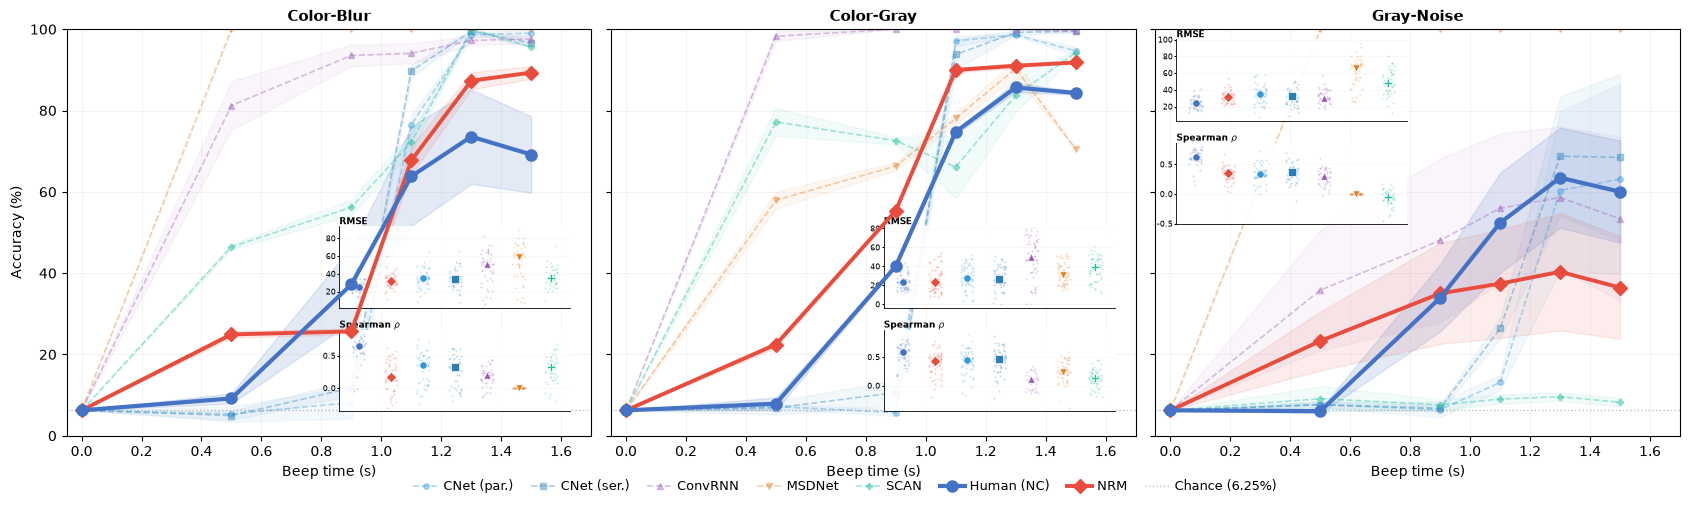

In [4]:
curves_by_model = {}
for (label, task), payload in curves.items():
    curves_by_model.setdefault(label, {})[task] = payload

full_by_model = {}
for (label, task), payload in full.items():
    full_by_model.setdefault(label, {})[task] = payload

# `full_by_model` adds two insets per panel — the per-observer
# RMSE and Spearman strips — drawn from the same arrays the tables use.
fig = figures.plot_sat_bench(
    curves_by_model,
    save_path=OUTDIR / f'SAT_bench{TAG}.pdf',
    tasks=TASKS,
    n_choices=N_CHOICES,
    full_by_model=full_by_model,
)
plt.show()

## 4. Table `tab:sat_perobs` — per perturbation level

Three metrics per model: **RMSE** between the model's and each observer's SAT
curve, the category-wise **Spearman $r$** against the observers, and the
Weibull **steepness $\mathcal{K}$** of the fitted curve. 

In [5]:
LEVELS = tables.SAT_TASK_LEVELS


def _triple(payload, level, who):
    # (RMSE, Spearman r, steepness) at one level, for 'model' or 'human'.
    if payload is None:
        return (np.nan,) * 3
    if who == 'model':
        rmse = payload['ermse'].get('model_by_level_median', {}).get(level)
        rho = payload['spearman'].get('model_by_level_median', {}).get(level)
    else:
        rmse = payload['ermse'].get('human_by_level_median', {}).get(level)
        rho = payload['spearman'].get('human_by_level', {}).get(level)
    kappa = (payload.get('steepness', {}).get(level) or {}).get(who, [None])[0]
    return tuple(np.nan if v is None else float(v) for v in (rmse, rho, kappa))


model_vals, human_vals = {}, {}
for (label, task), payload in full.items():
    for level in LEVELS[task]:
        model_vals[(label, task, level)] = _triple(payload, level, 'model')
        # The human curves are the same behavioural data for every model.
        if human_vals.get((task, level)) is None or not np.isfinite(
                human_vals.get((task, level), (np.nan,))[0]):
            human_vals[(task, level)] = _triple(payload, level, 'human')

perobs_tex = tables.sat_per_level_table(model_vals, human_vals)
(OUTDIR / f'sat_perobs_table{TAG}.tex').write_text(perobs_tex)
print(perobs_tex)
print(f"\nSaved -> {(OUTDIR / f'sat_perobs_table{TAG}.tex').relative_to(ROOT)}")

\begin{table}[ht]
  \centering
  \caption{Speed--accuracy tradeoff (SAT) on the SATBench benchmark \citep{subramanian2022satbench}, evaluated across input types and perturbation levels. Human~(NC): median metric per-observer per-level (noise ceiling). Model rows report the raw metric value; superscript grey values show $|\Delta|$ from Human~(NC) for RMSE and $\mathcal{K}$. Column $r$ is intrinsically human-relative and carries no superscript delta. \textit{Avg} = mean over perturbation levels. \textbf{Bold} = best, \underline{underline} = second best per column (ranked by smallest $|\Delta|$ for RMSE and $\mathcal{K}$; largest value for $r$).}
  \label{tab:sat_perobs}
  \scriptsize
  \setlength{\tabcolsep}{2.2pt}
  \resizebox{\linewidth}{!}{%
  \begin{tabular}{@{} ll lll llll llll @{}}
    \toprule
    & & \multicolumn{3}{c}{\textbf{Color \& Gray}} & \multicolumn{4}{c}{\textbf{Gray \& Noise} ($\sigma$)} & \multicolumn{4}{c}{\textbf{Color \& Blur} ($\sigma$)} \\
    \cmidrule(lr){3-5} \

## 5. Table `tab:sat_global` — averaged over perturbation levels

Point estimates are the *Avg* columns of the table above. The 95 % intervals
come from resampling **observers** (B = 1000).

In [6]:
from metrics.relational_metrics import compute_per_obs_bootstrap_ci

cis = {}
for (label, task), payload in full.items():
    ermse_obs = [v for v in payload.get('ermse', {}).get('model_per_obs', [])
                 if v is not None]
    sp_obs = [v for v in payload.get('spearman', {}).get('model_per_obs', [])
              if v is not None]
    cis[(label, task)] = {
        'RMSE': compute_per_obs_bootstrap_ci(ermse_obs, B=1000, seed=42),
        'r': compute_per_obs_bootstrap_ci(sp_obs, B=1000, seed=42),
    }
    print(f'  {label:12s} {task:12s} n_obs={len(ermse_obs):3d}')

global_tex = tables.sat_global_table(model_vals, human_vals, cis, tasks=TASKS)
(OUTDIR / f'sat_global_table{TAG}.tex').write_text(global_tex)
print()
print(global_tex)
print(f"\nSaved -> {(OUTDIR / f'sat_global_table{TAG}.tex').relative_to(ROOT)}")

  NRM          color-blur   n_obs= 45
  CNet(par.)   color-blur   n_obs= 45
  CNet(ser.)   color-blur   n_obs= 45
  ConvRNN      color-blur   n_obs= 45
  MSDNet       color-blur   n_obs= 45
  SCAN         color-blur   n_obs= 45
  NRM          color-gray   n_obs= 58
  CNet(par.)   color-gray   n_obs= 58
  CNet(ser.)   color-gray   n_obs= 58
  ConvRNN      color-gray   n_obs= 58
  MSDNet       color-gray   n_obs= 58
  SCAN         color-gray   n_obs= 58
  NRM          gray-noise   n_obs= 45
  CNet(par.)   gray-noise   n_obs= 45
  CNet(ser.)   gray-noise   n_obs= 45
  ConvRNN      gray-noise   n_obs= 45
  MSDNet       gray-noise   n_obs= 45
  SCAN         gray-noise   n_obs= 45

\begin{table}[t]
  \centering
  \caption{%
        SATBench: Global comparison averaged across all perturbation levels. 
        RMSE, Spearman's correlation ($r$) and curve steepness ($\mathcal{K}$) assess SAT alignment. \textbf{Bold} and \underline{underline} indicate the best and second-best performing models, 